# Ensemble
# Bagging(RandomForest): 머신러닝 분류(classification) 모델

# A) 이진분류 모델 구현 

## 1) 문제 정의 

- 와인의 특성을 통해 레드와인인지 화이트와인인지 예측하는 이진분류 모델을 구현해보자 

In [10]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics 

## 2. 데이터 로드 및 탐색

- 데이터: 와인 데이터
- 포맷: csv 
- feature(특성):
    - alcoho: 알콜 도수 
    - sugar: 당도
    - pH: 산성도
- class: 0.0(레드와인), 1.0(화이트와인)

In [2]:
df = pd.read_csv("https://bit.ly/wine_csv_data")

print(df.shape)
df.head()

(6497, 4)


,alcohol,sugar,pH,class
0,9.4,1.9,3.51,0.0
1,9.8,2.6,3.20,0.0
2,9.8,2.3,3.26,0.0
3,9.8,1.9,3.16,0.0
4,9.4,1.9,3.51,0.0


## 3. 데이터 분리 

### 3.1 features와 target으로 분리 

In [3]:
X = df.iloc[:, :-1]
y = df[["class"]]

print(X.shape, y.shape)

(6497, 3) (6497, 1)


### 3.2 Train, Test 분리 

In [6]:
# y의 클래스 분포 확인 
print("y의 클래스 분포 확인:\n", y.value_counts())
print()

# train, test로 데이터 분리 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

y의 클래스 분포 확인:
 class
1.0      4898
0.0      1599
Name: count, dtype: int64

(5197, 3) (1300, 3) (5197, 1) (1300, 1)


## 4. 전처리: 스케일링 생략 

- Tree기반 모델은 특성의 스케일이 모델에 영향을 미치지 않기 때문에 해당 과정은 생략 가능 

## 5. 모델 학습 및 평가 

- RandomForestClassifier
    - n_jobs
        - RandomForestClassifier는 기본적으로 100개의 결정트리를 사용하므로 n_jobs 매개변수도 -1로 지정하여 모든 CPU 코어 사용
        - 병렬 처리에 사용할 CPU 코어 수를 지정하는 파라미터 
        - -1: 가능한 모든 CPU 코어를 사용해서 병렬 처리 -> 학습시간 단축과 컴퓨터의 모든 코어를 효율적으로 사용가능하며, 예측에 사용할 경우 병렬 처리로 인해 여러 트리에서 동시에 예측 처리가 가능 
        - n_jobs=2처럼 일부만 쓰는것도 가능하지만, 일반적으로는 -1일 가장 많이 씀 
    - return_train_score=True: 훈련 데이터에 대한 score도 반환할지 여부

### 5.1 기본 매개변수로 모델 학습 및 평가  

In [8]:
# 모델 객체 정의
model_default = RandomForestClassifier(n_jobs=-1, random_state=42)

- 교차 검증 통해 모델 성능 평가 
- 교차 검증: 데이터를 여러번 나눠 학습 및 평가를 진행하는 방식으로 모델이 우연히 성능이 잘 나왔을 가능성을 방지하고 일반화 성능을 판단하기 위한 방식
- 교차 검증을 하는 경우
    - 데이터가 많지 않을 때: 데이터를 여러 번 나누어 최대한 효율적으로 사용하고 싶을 때
    - 과적합 여부를 확인하고 싶을 때: 훈련 데이터와 검증 데이터를 여러 번 바꿔가며 평가해 모델이 특정 데이터에 치우치지 않는지 확인할 때

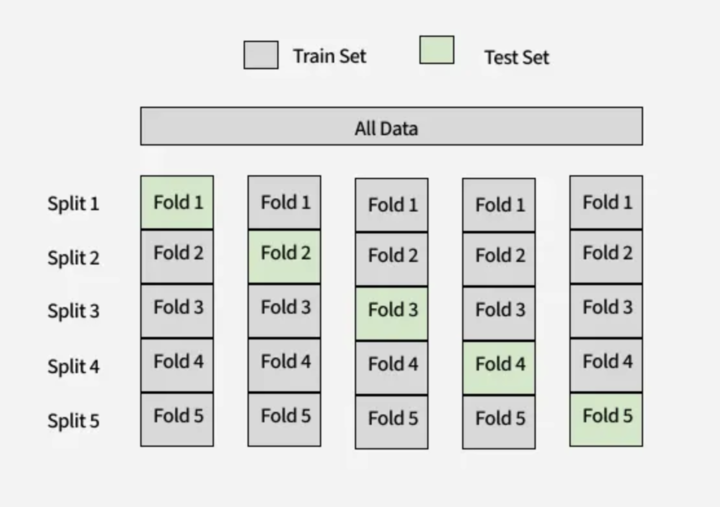


In [11]:
# 교차검증을 통해 성능평가 (기본 5-fold 사용)
scores_1 = cross_validate(
    model_default,
    X_train,
    y_train,
    return_train_score=True, # 훈련 점수 같이 반환 -> 검증 점수와 비교하여 과대/과소 적합 판단 위함
    n_jobs=-1
)

scores_1 # 5개의 fold의 정확도가 반환됨 

/opt/anaconda3/envs/sesac-env/lib/python3.11/site-packages/sklearn/base.py:1336: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/anaconda3/envs/sesac-env/lib/python3.11/site-packages/sklearn/base.py:1336: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/anaconda3/envs/sesac-env/lib/python3.11/site-packages/sklearn/base.py:1336: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/anaconda3/envs/sesac-env/lib/python3.11/site-packages/sklearn/base.py:1336: DataConversionWarning: A column-vector y was passed when a 1d array

{'fit_time': array([0.137707  , 0.13694811, 0.13731933, 0.14010501, 0.13318276]),
 'score_time': array([0.02627206, 0.02646494, 0.02600384, 0.01689506, 0.02684522]),
 'test_score': array([0.90384615, 0.89903846, 0.88739172, 0.89316651, 0.88354187]),
 'train_score': array([0.99807554, 0.99807554, 0.9983165 , 0.998076  , 0.9983165 ])}

In [ ]:
"""
{'fit_time': array([0.11745715, 0.11960196, 0.12929773, 0.13215995, 0.12784481]),     # fold마다 학습에 걸린 시간
 'score_time': array([0.03041291, 0.02877617, 0.01483011, 0.01562214, 0.01602888]),   # 모델이 결과를 예측하는 데 걸린 시간(초)
 'test_score': array([0.90384615, 0.89903846, 0.88739172, 0.89316651, 0.88354187]),   # 검증 세트 성능(일반화 성능)
 'train_score': array([0.99807554, 0.99807554, 0.9983165 , 0.998076  , 0.9983165 ])}  # 훈련세트 성능 (과적합 여부 판단용)
"""

In [ ]:
import numpy as np 

test_score = np.round(np.mean(scores_1["test_score"]), 4)
train_score = np.round(np.mean(scores_1["train_score"]), 4)

print("train fold score:", train_score)
print("test fold score:", test_score) 

# 과대적합에 빠진것을 알 수 있음 

train fold score: 0.9982
test fold score: 0.8934


- 특성 중요도 확인 -> DecisionTree의 특성 중요도와 비교해보기 

In [ ]:
model_default.fit(X_train, y_train)

print("특성 이름:", X_train.columns)
model_default.feature_importances_

/opt/anaconda3/envs/sesac-env/lib/python3.11/site-packages/sklearn/base.py:1336: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


array([0.2304613 , 0.50120112, 0.26833757])